<a href="https://colab.research.google.com/github/anhthuvo0506-web/Colab-AI-Project/blob/main/KNN_ConditionalGAN_ViTriChuaKhaoSat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# KNN–Conditional GAN: tăng cường Wi‑Fi Fingerprint tại vị trí chưa khảo sát

**Notebook mới, code mới — không sử dụng checkpoint hoặc kết quả của notebook cũ.**

Mục tiêu: KNN dự đoán fingerprint ban đầu từ các tọa độ đã khảo sát; Generator có điều kiện học phần hiệu chỉnh để sinh fingerprint tại tọa độ chưa khảo sát. So sánh trung thực với KNN độc lập và các đối chứng. Không mặc định cGAN phải thắng.

Luồng: **RP khảo sát → KNN → tọa độ + RSSI KNN + mask hỗ trợ + nhiễu → Generator hiệu chỉnh → fingerprint tổng hợp**.

**Cách chạy:** dùng Google Colab, chọn Runtime → Change runtime type → GPU nếu có; chạy tuần tự các cell. Chọn `smoke_test=True` để kiểm tra nhanh trước; kết quả smoke không dùng cho kết luận nghiên cứu. Chạy đầy đủ mặc định có 3 seed huấn luyện, 4 mạng × 3 tầng × 3 seed = 36 lần huấn luyện, có early stopping.

Dữ liệu: `DATASET_DLULIB.zip`. Không cần đổi Excel sang CSV.

In [1]:
%pip -q install "scikit-learn>=1.6,<2" openpyxl
# Colab đã có PyTorch. Nếu chạy ngoài Colab, cài thêm torch, numpy, pandas, matplotlib.

## 1. Thiết kế đánh giá — đọc trước khi chạy

- Đọc `Train_F1_3`, `Train_F2_3`, `Train_F3_3`: fingerprint cấp RP, không dùng `_1` có thể chứa dòng không hợp lệ hoặc `_2` có phép đo lặp.
- Các workbook Train/Test chia sẻ nhiều ID RP. Vì vậy **không coi file Test là tập vị trí chưa khảo sát độc lập**. File Test chỉ được kiểm tra mức trùng ID trong notebook này.
- Thí nghiệm chính giữ lại **nguyên tọa độ/RP** trong workbook Train làm validation và test: mặc định khoảng 65%/15%/20%. Không đưa bất kỳ RSSI của RP validation/test vào tham chiếu KNN hay minibatch huấn luyện.
- `random_rp`: kiểm tra nội suy vào các vị trí bị giữ lại. `spatial_block`: giữ lại các block không gian, khó hơn; dùng thư mục đầu ra khác và chọn kích thước block trước khi xem kết quả test.
- Đầu vào KNN cho RP train được tạo bằng **cross-fitting theo nhóm tọa độ**: RP cần dự đoán không nằm trong tập láng giềng. Không cho RP tự khớp chính nó.
- Tọa độ được chuẩn hóa bằng **tập train** cho neural network. KNN không gian dùng tọa độ nguồn. Không dùng độ cao Z minh họa.
- Sentinel 100 / −100 và RSSI ngoài (−100, 0) là thiếu; loss và sai số tái tạo chỉ tính trên ô thật hợp lệ.
- Khi một AP hoàn toàn thiếu ở tập tham chiếu, dùng prior khai báo −75 dBm, đặt support=0 và ghi AP đó vào `preprocessing.json`. Không lấy trung bình từ target/validation/test.


## 2. Cấu hình và thư viện

Bạn có thể chỉnh cấu hình trước khi chạy. Tham số loss/kiến trúc đang là cấu hình khởi đầu, chưa phải cấu hình tối ưu. K của spatial KNN được chọn bằng validation. Giữ test kín khi điều chỉnh. RSSI chuẩn hóa tuyến tính cố định từ dBm, không fit trên test.

In [2]:
from pathlib import Path
import io, json, zipfile, hashlib, random, copy, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.neighbors import NearestNeighbors, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn

CONFIG = dict(
    zip_path='DATASET_DLULIB.zip', output_dir='knn_cgan_results',
    floors=['F1','F2','F3'], split_seed=2026, split_mode='random_rp',
    spatial_block_size=6.0, test_fraction=0.20, val_fraction=0.15,
    knn_grid=[3,5,7,9], oof_folds=5,
    train_seeds=[42,52,62], epochs=250, patience=35, min_epochs=30,
    batch_size=64, width=64, noise_dim=8, lr=0.0003,
    adversarial_weight=0.02, max_residual_db=25.0,
    mc_samples=16, inference_seed=9091,
    augmentation_ratios=[0.25,0.5,1.0], synthetic_mask_threshold=0.5,
    candidate_distance_multiplier=2.5, synthetic_noise_seed=715,
    smoke_test=False,
)
AP = [f'AP{i}' for i in range(1,18)]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def dbm_to_norm(y):
    return (np.asarray(y,dtype=np.float32)+100.0)/100.0

def norm_to_dbm(y):
    return np.clip(np.asarray(y),0.0001,0.9999)*100.0-100.0

def metric(y,p):
    mask=np.isfinite(y)
    if not mask.any(): return dict(MAE=np.nan,RMSE=np.nan,N_cells=0)
    if not np.isfinite(p[mask]).all(): raise ValueError('Prediction missing on evaluated cell')
    e=np.asarray(p)[mask]-np.asarray(y)[mask]
    return dict(MAE=float(np.abs(e).mean()),RMSE=float(np.sqrt(np.mean(e**2))),N_cells=int(mask.sum()))

def coordinate_keys(xy):
    return np.array([f'{x:.5f}|{y:.5f}' for x,y in np.asarray(xy)])

## 3. Nạp và kiểm tra dữ liệu

Chỉ đọc Excel và thống kê; không chạy bất kỳ mã nào bên trong tệp dữ liệu.

In [3]:
def load_floors(zip_path, floors):
    data={}; audits=[]
    with zipfile.ZipFile(zip_path) as z:
        names=z.namelist()
        def read(name,sheet):
            hits=[n for n in names if n.split('/')[-1]==name]
            if len(hits)!=1: raise ValueError(f'Expected exactly one {name}, got {hits}')
            return pd.read_excel(io.BytesIO(z.read(hits[0])),sheet_name=sheet)
        for f in floors:
            df=read(f'DLULIB_Train_{f}.xlsx',f'Train_{f}_3')
            df.columns=df.columns.astype(str).str.strip()
            required=['ID_RP','X','Y']+AP
            if not set(required)<=set(df): raise ValueError(f'{f}: missing required columns')
            df=df[required].copy()
            for col in required: df[col]=pd.to_numeric(df[col],errors='coerce')
            if df[['ID_RP','X','Y']].isna().any().any() or df.ID_RP.duplicated().any():
                raise ValueError(f'{f}: invalid coordinates/IDs')
            if df[['X','Y']].duplicated().any():
                raise ValueError(f'{f}: duplicate coordinates: resolve/aggregate before experiment')
            for col in AP: df[col]=df[col].where((df[col]>-100)&(df[col]<0))
            test=read(f'DLULIB_Test_{f}.xlsx',f'Test_{f}_3')
            test.columns=test.columns.astype(str).str.strip()
            overlap=len(set(df.ID_RP)&set(pd.to_numeric(test.ID_RP,errors='coerce')))
            audits.append(dict(Floor=f,Original_RP=len(df),AP=17,Missing_cells=int(df[AP].isna().sum().sum()),External_test_ID_overlap=overlap,External_test_rows=len(test)))
            data[f]=df.reset_index(drop=True)
    return data,pd.DataFrame(audits)

## 4. Chia tập nguyên RP / block không gian

Có assertion kiểm tra ID và nhóm tọa độ không giao nhau.

In [4]:
def split_floor(df,cfg):
    if cfg['split_mode']=='random_rp': groups=coordinate_keys(df[['X','Y']])
    elif cfg['split_mode']=='spatial_block':
        blocks=np.floor(df[['X','Y']].to_numpy()/cfg['spatial_block_size']).astype(int)
        groups=np.array([f'{x}:{y}' for x,y in blocks])
    else: raise ValueError('split_mode must be random_rp or spatial_block')
    u=np.unique(groups)
    if len(u)<8: raise ValueError('Too few groups; reduce spatial_block_size')
    train_val,test_g=train_test_split(u,test_size=cfg['test_fraction'],random_state=cfg['split_seed'])
    train_g,val_g=train_test_split(train_val,test_size=cfg['val_fraction']/(1-cfg['test_fraction']),random_state=cfg['split_seed']+1)
    parts={name:np.flatnonzero(np.isin(groups,gs)) for name,gs in [('train',train_g),('val',val_g),('test',test_g)]}
    for a,b in itertools.combinations(parts,2):
        assert not set(df.iloc[parts[a]].ID_RP)&set(df.iloc[parts[b]].ID_RP)
        assert not set(groups[parts[a]])&set(groups[parts[b]])
    if min(map(len,parts.values()))<3: raise ValueError('Split too small')
    return parts,groups

## 5. Spatial KNN và dự đoán ngoài fold

Láng giềng được chọn riêng cho từng AP có số đo hợp lệ. Cross-fitting dùng các fold chỉ trong tập train.

In [5]:
class SpatialKNN:
    def __init__(self,k=5): self.k=int(k)
    def fit(self,xy,y):
        self.xy=np.asarray(xy,float);self.y=np.asarray(y,float)
        self.valid=np.isfinite(self.y)
        counts=self.valid.sum(0)
        self.mean=np.divide(np.nansum(self.y,axis=0),counts,out=np.full(17,-75.),where=counts>0)
        return self
    def predict(self,xy):
        xy=np.asarray(xy,float);dist=np.sqrt(((xy[:,None,:]-self.xy[None,:,:])**2).sum(2))
        pred=np.tile(self.mean,(len(xy),1));support=np.zeros_like(pred)
        for a in range(17):
            refs=np.flatnonzero(self.valid[:,a])
            if not len(refs): continue
            ds=dist[:,refs];order=np.argsort(ds,axis=1)[:,:min(self.k,len(refs))]
            dd=np.take_along_axis(ds,order,axis=1)
            exact=dd<1e-8
            w=1/np.maximum(dd,1e-6)**2
            for i in range(len(xy)):
                if exact[i].any(): w[i]=exact[i].astype(float)
            vals=self.y[refs[order],a]
            pred[:,a]=(w*vals).sum(1)/w.sum(1);support[:,a]=1
        return pred.astype(np.float32),support.astype(np.float32)
    def presence(self,xy):
        d=((np.asarray(xy)[:,None,:]-self.xy[None,:,:])**2).sum(2)
        ix=np.argsort(d,axis=1)[:,:min(self.k,len(self.xy))]
        return self.valid[ix].mean(1)


def crossfit_knn(xy,y,k,folds,seed):
    # A held-out RP and every row of its coordinate group are absent from references.
    groups=coordinate_keys(xy);folds=min(folds,len(np.unique(groups)))
    if folds<2: raise ValueError('At least two OOF groups required')
    splitter=GroupKFold(n_splits=folds,shuffle=True,random_state=seed)
    pred=np.zeros_like(y,dtype=np.float32);support=np.zeros_like(pred);audit=[]
    for fold,(tr,held) in enumerate(splitter.split(xy,groups=groups)):
        assert not set(groups[tr])&set(groups[held])
        knn=SpatialKNN(k).fit(xy[tr],y[tr]);pred[held],support[held]=knn.predict(xy[held])
        audit.append(dict(fold=fold,n_reference=len(tr),n_query=len(held),coordinate_overlap=0))
    return pred,support,audit

## 6. Mạng sinh, discriminator và chọn checkpoint

Các phương pháp: **AP_Mean**, **KNN** (k chọn bằng validation), **cGAN_XY** (tọa độ+nhiễu), **KNN_MLP** (hiệu chỉnh xác định, không discriminator), **KNN_NoAdv** (cùng Generator/nhiễu như mô hình kết hợp nhưng không loss đối kháng), **KNN_cGAN** (hiệu chỉnh có điều kiện đối kháng).

KNN_NoAdv là đối chứng gần nhất để kiểm tra lợi ích của loss đối kháng. Mask tính loss là mask dữ liệu thật và không được đưa vào Generator như thông tin target. Checkpoint chọn bằng MAE validation dBm, không chọn epoch bằng test. MAE/RMSE chính dùng trung bình 16 lần sinh nhiễu, báo cáo thêm một lần sinh riêng để thấy khác biệt. Độ lệch chuẩn trong bảng tổng hợp là **qua seed huấn luyện**, không phải 16 seed nhiễu.

In [6]:
class Generator(nn.Module):
    def __init__(self,cond_dim,noise_dim,width,residual,max_delta):
        super().__init__();self.noise_dim=noise_dim;self.residual=residual;self.max_delta=max_delta/100.
        self.net=nn.Sequential(nn.Linear(cond_dim+noise_dim,width),nn.LeakyReLU(.2),nn.Linear(width,width),nn.LeakyReLU(.2),nn.Linear(width,17))
    def forward(self,c,coarse,z):
        out=self.net(torch.cat([c,z],dim=1))
        return torch.clamp(coarse+self.max_delta*torch.tanh(out),0.,1.) if self.residual else torch.sigmoid(out)

class Discriminator(nn.Module):
    def __init__(self,cond_dim,width):
        super().__init__();self.net=nn.Sequential(nn.Linear(cond_dim+34,width),nn.LeakyReLU(.2),nn.Linear(width,width//2),nn.LeakyReLU(.2),nn.Linear(width//2,1))
    def forward(self,c,y,mask):
        # Same ground-truth validity mask for real/fake; unknown cells are never treated as measurements.
        return self.net(torch.cat([c,y*mask,mask],dim=1))


def condition(method,xy_scaled,coarse,support):
    return xy_scaled if method=='cGAN_XY' else np.concatenate([xy_scaled,dbm_to_norm(coarse),support],axis=1)

def predict_generator(model,c,coarse,cfg,seed=None,n_samples=None):
    model.eval();samples=n_samples or cfg['mc_samples'];seed=cfg['inference_seed'] if seed is None else seed
    c=torch.as_tensor(c,dtype=torch.float32,device=DEVICE);b=torch.as_tensor(dbm_to_norm(coarse),device=DEVICE)
    rng=torch.Generator(device=DEVICE).manual_seed(seed)
    with torch.no_grad():
        predictions=[]
        for _ in range(samples if model.noise_dim else 1):
            z=torch.randn((len(c),model.noise_dim),generator=rng,device=DEVICE)
            predictions.append(model(c,b,z).cpu().numpy())
    return norm_to_dbm(np.mean(predictions,axis=0))


def fit_generator(method,seed,train,val,cfg,out_dir):
    seed_all(seed);c,y,b=train;cv,yv,bv=val
    adversarial=method in ['cGAN_XY','KNN_cGAN'];noise=0 if method=='KNN_MLP' else cfg['noise_dim']
    g=Generator(c.shape[1],noise,cfg['width'],method!='cGAN_XY',cfg['max_residual_db']).to(DEVICE)
    d=Discriminator(c.shape[1],cfg['width']).to(DEVICE) if adversarial else None
    go=torch.optim.AdamW(g.parameters(),lr=cfg['lr'],weight_decay=1e-4)
    do=torch.optim.AdamW(d.parameters(),lr=cfg['lr'],weight_decay=1e-4) if d else None
    ct=torch.tensor(c,dtype=torch.float32,device=DEVICE);bt=torch.tensor(dbm_to_norm(b),device=DEVICE)
    valid=np.isfinite(y);yt=torch.tensor(dbm_to_norm(np.where(valid,y,-75)),device=DEVICE);mt=torch.tensor(valid,dtype=torch.float32,device=DEVICE)
    if not valid.any(): raise ValueError('No valid training RSSI')
    bce=nn.BCEWithLogitsLoss();history=[];best=float('inf');state=None;stale=0
    for epoch in range(1,cfg['epochs']+1):
        g.train();losses=[];dloss=[]
        for ix in torch.randperm(len(c),device=DEVICE).split(cfg['batch_size']):
            cc,bb,yy,mm=ct[ix],bt[ix],yt[ix],mt[ix]
            if mm.sum()==0: continue
            z=torch.randn((len(ix),noise),device=DEVICE)
            if d:
                d.train();do.zero_grad();fake=g(cc,bb,z).detach()
                ld=.5*(bce(d(cc,yy,mm),torch.ones((len(ix),1),device=DEVICE))+bce(d(cc,fake,mm),torch.zeros((len(ix),1),device=DEVICE)))
                ld.backward();do.step();dloss.append(float(ld.detach()))
                for p in d.parameters(): p.requires_grad_(False)
            go.zero_grad();fake=g(cc,bb,torch.randn((len(ix),noise),device=DEVICE))
            recon=(torch.abs(fake-yy)*mm).sum()/mm.sum()
            adv=bce(d(cc,fake,mm),torch.ones((len(ix),1),device=DEVICE)) if d else torch.tensor(0.,device=DEVICE)
            loss=recon+cfg['adversarial_weight']*adv;loss.backward();nn.utils.clip_grad_norm_(g.parameters(),5.);go.step()
            if d:
                for p in d.parameters():p.requires_grad_(True)
            losses.append(float(recon.detach()))
        vp=predict_generator(g,cv,bv,cfg);score=metric(yv,vp)['MAE']
        history.append(dict(epoch=epoch,train_L1_norm=np.mean(losses),discriminator_loss=np.mean(dloss) if dloss else np.nan,val_MAE_dBm=score))
        if score<best-1e-5:
            best=score;best_epoch=epoch;state={k:v.detach().cpu().clone() for k,v in g.state_dict().items()};stale=0
        else:stale+=1
        if epoch==1 or epoch%25==0:print(f'{method} seed={seed} epoch={epoch} val MAE={score:.4f} dBm')
        if epoch>=cfg['min_epochs'] and stale>=cfg['patience']:break
    if state is None:raise ValueError('No valid validation checkpoint')
    g.load_state_dict(state);out_dir.mkdir(parents=True,exist_ok=True)
    torch.save({'generator':state,'method':method,'seed':seed,'best_epoch':best_epoch,'validation_MAE':best,'config':cfg},out_dir/f'{method}_seed{seed}.pt')
    pd.DataFrame(history).to_csv(out_dir/f'{method}_seed{seed}_history.csv',index=False)
    return g,dict(Method=method,Seed=seed,Best_epoch=best_epoch,Validation_MAE=best,Parameters=sum(p.numel() for p in g.parameters())),pd.DataFrame(history)

## 7. Sinh tọa độ bổ sung

Tạo trung điểm các cặp RP train đủ gần. Loại tọa độ trùng RP train, validation, test và trùng nhau. Tọa độ validation/test chỉ dùng làm danh sách chặn trùng, không dùng RSSI. Chỉ sinh tối đa khoảng 100% số RP train; nếu không đủ ứng viên thì báo số thực tế. Đây là nội suy trong vùng khảo sát, không chứng minh khả năng ngoại suy sang vùng mới hoặc tòa nhà khác.

In [7]:
def synthetic_candidates(train_xy,reserved_xy,cfg):
    train_xy=np.asarray(train_xy);nn_model=NearestNeighbors(n_neighbors=min(9,len(train_xy))).fit(train_xy)
    distances,indices=nn_model.kneighbors(train_xy)
    scale=float(np.median(distances[:,1]));limit=scale*cfg['candidate_distance_multiplier']
    forbidden=set(coordinate_keys(np.vstack([train_xy,reserved_xy])));seen=set();candidates=[]
    for i in range(len(train_xy)):
        for dist,j in zip(distances[i,1:],indices[i,1:]):
            if dist>limit:continue
            midpoint=(train_xy[i]+train_xy[j])/2;key=coordinate_keys([midpoint])[0]
            if key in forbidden or key in seen:continue
            seen.add(key);candidates.append(midpoint)
    if not candidates:return np.empty((0,2))
    candidates=np.asarray(candidates)
    rng=np.random.default_rng(cfg['synthetic_noise_seed']);order=rng.permutation(len(candidates))
    candidates=candidates[order][:int(np.ceil(len(train_xy)*max(cfg['augmentation_ratios'])))]
    assert not set(coordinate_keys(candidates))&forbidden
    return candidates

## 8. Đánh giá giá trị tăng cường dữ liệu

Đây là thí nghiệm phụ để kiểm tra fingerprint sinh có ích hay không. Mô hình định vị nhận RSSI và dự đoán tọa độ. Imputer/StandardScaler chỉ fit trên RSSI train đo thật rồi giữ nguyên cho mọi phương pháp. K định vị chọn bằng validation, khác với K không gian ở bước trước. Đơn vị sai số vị trí theo tọa độ nguồn; chỉ gọi là mét khi tài liệu nguồn xác nhận.

In [8]:
class LocalizationFeatures:
    def fit(self,y):
        valid=np.isfinite(y);counts=valid.sum(0)
        self.mean=np.divide(np.nansum(y,axis=0),counts,out=np.full(17,-75.),where=counts>0)
        self.scaler=StandardScaler().fit(np.where(valid,y,self.mean));return self
    def transform(self,y):return self.scaler.transform(np.where(np.isfinite(y),y,self.mean))

def locate_error(train_y,train_xy,query_y,query_xy,features,k):
    m=KNeighborsRegressor(n_neighbors=min(k,len(train_xy)),weights='distance')
    m.fit(features.transform(train_y),train_xy);p=m.predict(features.transform(query_y))
    errors=np.linalg.norm(p-query_xy,axis=1)
    return dict(Mean_position_error=float(errors.mean()),Median_position_error=float(np.median(errors)),P90_position_error=float(np.quantile(errors,.9))),p

## 9. Pipeline thí nghiệm

Tỷ lệ bổ sung 25%/50%/100% chọn theo validation, cho phép chọn **0%** nếu thêm dữ liệu không có lợi. Không ép kết quả phải cải thiện. Cùng tọa độ ứng viên, cùng mask khả dụng ước lượng từ các RP train được dùng cho mọi phương pháp sinh, kể cả KNN, để đối chiếu công bằng. Mask này là quy tắc từ láng giềng, không phải số đo thật tại tọa độ sinh.

Chọn seed mô hình sinh bằng validation MAE; đánh giá định vị dùng seed đã chọn này, chưa phải thống kê nhiều lần huấn luyện định vị. Không dùng bảng test để quyết định seed/epoch/k/tỷ lệ.

In [9]:
def run_experiment(cfg):
    cfg=copy.deepcopy(cfg);out=Path(cfg['output_dir']);out.mkdir(parents=True,exist_ok=True)
    if cfg['smoke_test']:warnings.warn('SMOKE TEST ONLY: epochs/seeds reduced; not a scientific conclusion')
    data,audit=load_floors(cfg['zip_path'],cfg['floors']);audit.to_csv(out/'dataset_audit.csv',index=False)
    cfg['device']=str(DEVICE);cfg['dataset_sha256']=hashlib.sha256(Path(cfg['zip_path']).read_bytes()).hexdigest()
    (out/'config.json').write_text(json.dumps(cfg,indent=2));metrics=[];single_draw=[];checkpoints=[];localization=[];split_rows=[];histories={}
    for floor,df in data.items():
        print('\n'+'='*60+'\nFLOOR '+floor)
        indices,groups=split_floor(df,cfg);xy=df[['X','Y']].to_numpy(float);y=df[AP].to_numpy(float)
        tr,va,te=[indices[k] for k in ['train','val','test']]
        for part,ix in indices.items():
            for i in ix:split_rows.append(dict(Floor=floor,ID_RP=int(df.iloc[i].ID_RP),X=xy[i,0],Y=xy[i,1],Split=part,Group=groups[i]))
        floor_out=out/floor;floor_out.mkdir(exist_ok=True)
        df.iloc[tr].to_csv(floor_out/'training_reference.csv',index=False)
        scaler=StandardScaler().fit(xy[tr]);xy_scaled=scaler.transform(xy).astype(np.float32)
        k_scores=[]
        for k in cfg['knn_grid']:
            pred,_=SpatialKNN(k).fit(xy[tr],y[tr]).predict(xy[va]);k_scores.append(dict(k=k,**metric(y[va],pred)))
        k=min(k_scores,key=lambda r:r['MAE'])['k'];pd.DataFrame(k_scores).to_csv(floor_out/'knn_validation_selection.csv',index=False)
        reference=SpatialKNN(k).fit(xy[tr],y[tr]);coarse={};support={}
        coarse['train'],support['train'],oof_audit=crossfit_knn(xy[tr],y[tr],k,cfg['oof_folds'],cfg['split_seed'])
        pd.DataFrame(oof_audit).to_csv(floor_out/'oof_leakage_audit.csv',index=False)
        for part,ix in [('val',va),('test',te)]:coarse[part],support[part]=reference.predict(xy[ix])
        (floor_out/'preprocessing.json').write_text(json.dumps({'xy_mean':scaler.mean_.tolist(),'xy_scale':scaler.scale_.tolist(),'AP_train_mean':reference.mean.tolist(),'k':k,'no_support_APs':[AP[i] for i,n in enumerate(reference.valid.sum(0)) if n==0]},indent=2))
        for method,pred in [('AP_Mean',np.tile(reference.mean,(len(te),1))),('KNN',coarse['test'])]:
            metrics.append(dict(Floor=floor,Method=method,Seed=-1,k=k,**metric(y[te],pred)))
        # Candidate generation never reads validation/test RSSI.
        candidates=synthetic_candidates(xy[tr],xy[np.r_[va,te]],cfg)
        c_coarse,c_support=reference.predict(candidates)
        presence=reference.presence(candidates) if len(candidates) else np.empty((0,17))
        synthetic_mask=presence>=cfg['synthetic_mask_threshold']
        synth_predictions={'KNN':c_coarse};models={};best_val={}
        for method in ['cGAN_XY','KNN_MLP','KNN_NoAdv','KNN_cGAN']:
            cond={part:condition(method,xy_scaled[ix],coarse[part],support[part]) for part,ix in [('train',tr),('val',va),('test',te)]}
            best_val[method]=float('inf')
            for seed in cfg['train_seeds']:
                model,record,hist=fit_generator(method,seed,(cond['train'],y[tr],coarse['train']),(cond['val'],y[va],coarse['val']),cfg,floor_out/'checkpoints')
                checkpoints.append(dict(Floor=floor,**record));histories[(floor,method,seed)]=hist
                pred=predict_generator(model,cond['test'],coarse['test'],cfg)
                metrics.append(dict(Floor=floor,Method=method,Seed=seed,k=k,**metric(y[te],pred)))
                single=predict_generator(model,cond['test'],coarse['test'],cfg,n_samples=1)
                single_draw.append(dict(Floor=floor,Method=method,Seed=seed,**metric(y[te],single)))
                rows=pd.DataFrame({'ID_RP':df.iloc[te].ID_RP.to_numpy(),'X':xy[te,0],'Y':xy[te,1]})
                for j,a in enumerate(AP):rows[a+'_truth']=y[te,j];rows[a+'_pred']=pred[:,j]
                rows.to_csv(floor_out/f'{method}_seed{seed}_heldout_predictions.csv',index=False)
                if record['Validation_MAE']<best_val[method]:
                    best_val[method]=record['Validation_MAE'];models[method]=model;selected_seed=seed
                    (floor_out/f'{method}_selected.json').write_text(json.dumps(record,indent=2))
            if len(candidates):
                cc=condition(method,scaler.transform(candidates).astype(np.float32),c_coarse,c_support)
                synth_predictions[method]=predict_generator(models[method],cc,c_coarse,cfg,seed=cfg['synthetic_noise_seed'],n_samples=1)
            else:synth_predictions[method]=np.empty((0,17))
        features=LocalizationFeatures().fit(y[tr]);loc_scores=[]
        for lk in cfg['knn_grid']:
            score,_=locate_error(y[tr],xy[tr],y[va],xy[va],features,lk);loc_scores.append((score['Mean_position_error'],lk))
        loc_k=min(loc_scores)[1]
        base_val,_=locate_error(y[tr],xy[tr],y[va],xy[va],features,loc_k)
        base_test,_=locate_error(y[tr],xy[tr],y[te],xy[te],features,loc_k)
        localization.append(dict(Floor=floor,Method='Original_only',Ratio=0,Added_RP=0,Localization_k=loc_k,Validation_error=base_val['Mean_position_error'],**base_test))
        trials=[]
        for method,synthetic_y in synth_predictions.items():
            # Availability is estimated from train neighbors; not from target measurements.
            masked=np.where(synthetic_mask,synthetic_y,np.nan)
            usable=np.isfinite(masked).sum(1)>=3
            positions=candidates[usable];values=masked[usable]
            best=(base_val['Mean_position_error'],0,0)
            for ratio in cfg['augmentation_ratios']:
                count=min(len(positions),int(round(len(tr)*ratio)))
                if count==0:continue
                ay=np.vstack([y[tr],values[:count]]);ax=np.vstack([xy[tr],positions[:count]])
                val_score,_=locate_error(ay,ax,y[va],xy[va],features,loc_k)
                trials.append(dict(Method=method,Ratio=ratio,Added_RP=count,Validation_error=val_score['Mean_position_error']))
                if val_score['Mean_position_error']<best[0]:best=(val_score['Mean_position_error'],ratio,count)
            _,ratio,count=best
            test_score,_=locate_error(np.vstack([y[tr],values[:count]]),np.vstack([xy[tr],positions[:count]]),y[te],xy[te],features,loc_k)
            localization.append(dict(Floor=floor,Method=method,Ratio=ratio,Added_RP=count,Localization_k=loc_k,Validation_error=best[0],**test_score))
            frame=pd.DataFrame(values,columns=AP);frame.insert(0,'Y',positions[:,1]);frame.insert(0,'X',positions[:,0]);frame.insert(0,'Floor',floor)
            frame['Data_type']='SYNTHETIC_NOT_MEASURED';frame['Method']=method
            frame['Selected_for_augmentation']=np.arange(len(frame))<count
            frame.to_csv(floor_out/f'{method}_synthetic_candidates.csv',index=False)
        pd.DataFrame(trials).to_csv(floor_out/'augmentation_validation_selection.csv',index=False)
        (floor_out/'candidate_audit.json').write_text(json.dumps({'n_candidates':len(candidates),'n_train':len(tr),'overlap_with_train_val_test':0,'test_RSSI_used_for_selection':False,'position_unit':'source coordinate units; meters only if source documentation confirms'},indent=2))
    m=pd.DataFrame(metrics);m.to_csv(out/'reconstruction_by_training_seed.csv',index=False)
    pd.DataFrame(single_draw).to_csv(out/'reconstruction_single_noise_draw.csv',index=False)
    summary=m.groupby(['Floor','Method']).agg(MAE_mean=('MAE','mean'),MAE_std=('MAE','std'),RMSE_mean=('RMSE','mean'),RMSE_std=('RMSE','std'),N_training_runs=('Seed','size'),N_cells=('N_cells','first')).reset_index()
    summary.to_csv(out/'reconstruction_summary.csv',index=False)
    pd.DataFrame(checkpoints).to_csv(out/'checkpoint_selection.csv',index=False)
    pd.DataFrame(split_rows).to_csv(out/'split_manifest.csv',index=False)
    loc=pd.DataFrame(localization);loc.to_csv(out/'localization_selected_on_validation.csv',index=False)
    print('\nRSSI reconstruction (dBm):\n',summary.to_string(index=False))
    print('\nPositioning (source coordinate units):\n',loc.to_string(index=False))
    return dict(summary=summary,metrics=m,localization=loc,audit=audit,histories=histories,output_dir=out)

## 10. Biểu đồ và gói kết quả

In [10]:
def plot_results(result):
    out=result['output_dir'];s=result['summary'];loc=result['localization']
    for floor in s.Floor.unique():
        fig,axes=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
        sub=s[s.Floor==floor]
        for ax,key in zip(axes,['MAE','RMSE']):
            ax.bar(sub.Method,sub[key+'_mean'],yerr=sub[key+'_std'].fillna(0),capsize=3,color=['#64748b','#0891b2','#f59e0b','#7c3aed','#2563eb'][:len(sub)])
            ax.set(title=f'{floor} — {key}',ylabel='dBm');ax.tick_params(axis='x',rotation=30);ax.grid(axis='y',alpha=.2)
        fig.savefig(out/f'{floor}_reconstruction.png',dpi=160);plt.show();plt.close(fig)
        subloc=loc[loc.Floor==floor];fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True)
        ax.bar(subloc.Method,subloc.Mean_position_error,color='#0891b2');ax.set(title=f'{floor} — Original vs augmentation selected on validation',ylabel='Mean position error (source units)');ax.tick_params(axis='x',rotation=30)
        fig.savefig(out/f'{floor}_localization.png',dpi=160);plt.show();plt.close(fig)
    for floor in s.Floor.unique():
        fig,axes=plt.subplots(2,2,figsize=(13,8),constrained_layout=True)
        for ax,method in zip(axes.flat,['cGAN_XY','KNN_MLP','KNN_NoAdv','KNN_cGAN']):
            for (f,m,seed),hist in result['histories'].items():
                if f==floor and m==method:ax.plot(hist.epoch,hist.val_MAE_dBm,label=f'seed {seed}')
            ax.set(title=f'{floor} — {method}',xlabel='Epoch',ylabel='Validation MAE (dBm)');ax.legend();ax.grid(alpha=.2)
        fig.savefig(out/f'{floor}_validation_curves.png',dpi=160);plt.show();plt.close(fig)
    archive=out.parent/(out.name+'.zip')
    with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
        for p in sorted(out.rglob('*')):
            if p.is_file():z.write(p,p.relative_to(out))
    return archive

## 11. Hàm sinh tại tọa độ mới

Sau khi chạy pipeline, có thể nhập tọa độ nguồn bất kỳ; không cần RSSI đo tại vị trí đó. Chỉ nên diễn giải các điểm trong vùng có hỗ trợ từ RP train. Cột AP_available là ước lượng khả dụng từ train, không phải xác nhận AP được đo tại vị trí mới. Chỉ load checkpoint do chính notebook này tạo.

In [11]:
def generate_at_coordinates(output_dir,floor,query_xy,method='KNN_cGAN',seed=1107):
    root=Path(output_dir);folder=root/floor
    cfg=json.loads((root/'config.json').read_text());meta=json.loads((folder/'preprocessing.json').read_text())
    selected=json.loads((folder/f'{method}_selected.json').read_text())
    reference=pd.read_csv(folder/'training_reference.csv')
    xy=reference[['X','Y']].to_numpy(float);y=reference[AP].to_numpy(float);q=np.asarray(query_xy,float)
    if q.ndim!=2 or q.shape[1]!=2 or not np.isfinite(q).all():raise ValueError('query_xy must be finite Nx2 coordinates')
    if set(coordinate_keys(q))&set(coordinate_keys(xy)):warnings.warn('Some queried locations were surveyed; these are not unseen-location examples')
    spatial=SpatialKNN(meta['k']).fit(xy,y);coarse,support=spatial.predict(q)
    qs=((q-np.asarray(meta['xy_mean']))/np.asarray(meta['xy_scale'])).astype(np.float32)
    c=condition(method,qs,coarse,support)
    g=Generator(c.shape[1],0 if method=='KNN_MLP' else cfg['noise_dim'],cfg['width'],method!='cGAN_XY',cfg['max_residual_db']).to(DEVICE)
    # Only load a checkpoint generated by this notebook; never unpickle arbitrary uploads.
    state=torch.load(folder/'checkpoints'/f'{method}_seed{selected["Seed"]}.pt',map_location=DEVICE,weights_only=True)
    g.load_state_dict(state['generator']);pred=predict_generator(g,c,coarse,cfg,seed=seed,n_samples=1)
    valid=spatial.presence(q)>=cfg['synthetic_mask_threshold']
    frame=pd.DataFrame(pred,columns=AP);frame.insert(0,'Y',q[:,1]);frame.insert(0,'X',q[:,0]);frame.insert(0,'Floor',floor)
    for j,a in enumerate(AP):frame[a+'_available']=valid[:,j]
    frame['Data_type']='SYNTHETIC_NOT_MEASURED';frame['Method']=method
    return frame

## 12. Chọn dữ liệu đầu vào

Chọn file `DATASET_DLULIB.zip` khi Colab hỏi. Không cần giải nén thủ công. Nếu chạy trên máy cá nhân, đặt ZIP cùng thư mục notebook hoặc chỉnh `CONFIG['zip_path']`.

In [12]:
zip_path = Path(CONFIG['zip_path'])
if not zip_path.is_file():
    colab_default = Path('/content/DATASET_DLULIB.zip')
    if colab_default.is_file():
        zip_path = colab_default
    else:
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError("Đặt DATASET_DLULIB.zip cạnh notebook hoặc sửa CONFIG['zip_path'].")
        uploaded = files.upload()
        candidates = [Path(name) for name in uploaded if name.lower().endswith('.zip')]
        if len(candidates) != 1:
            raise ValueError('Chỉ chọn một file DATASET_DLULIB.zip.')
        zip_path = candidates[0]
CONFIG['zip_path'] = str(zip_path)
print('Dữ liệu:', zip_path)
print('Thiết bị:', DEVICE)
loaded, inventory = load_floors(zip_path, CONFIG['floors'])
display(inventory)
for floor, df in loaded.items():
    parts, _ = split_floor(df, CONFIG)
    print(floor, {name: len(ix) for name, ix in parts.items()})

Saving DATASET_DLULIB.zip to DATASET_DLULIB.zip
Dữ liệu: DATASET_DLULIB.zip
Thiết bị: cuda


,Floor,Original_RP,AP,Missing_cells,External_test_ID_overlap,External_test_rows
0,F1,314,17,934,314,314
1,F2,186,17,267,186,186
2,F3,150,17,312,150,150


F1 {'train': 203, 'val': 48, 'test': 63}
F2 {'train': 120, 'val': 28, 'test': 38}
F3 {'train': 97, 'val': 23, 'test': 30}


## 13. Chạy thử hoặc chạy nghiên cứu

**Lần đầu có thể chọn `SMOKE_TEST = True`** để kiểm tra file, GPU/CPU, checkpoint và quy trình xuất. Chế độ này giảm epoch/seed và không có giá trị kết luận mô hình nào tốt hơn. Không tối ưu tham số theo các con số test của smoke.

Sau đó dùng `False` để huấn luyện đầy đủ. Thời gian phụ thuộc thiết bị và early stopping. Các run dùng thư mục đầu ra tách biệt với notebook cũ. Chạy lại cùng thư mục sẽ ghi đè kết quả của chính run mới; dùng tên thư mục khác khi đổi thiết kế. Không thay đổi split để tìm kết quả test đẹp.

In [13]:
SMOKE_TEST = False  # đổi True để kiểm tra nhanh
cfg = copy.deepcopy(CONFIG)
cfg['smoke_test'] = SMOKE_TEST
cfg['output_dir'] = 'KNN_CGAN_NEW_smoke' if SMOKE_TEST else 'KNN_CGAN_NEW_results'
if SMOKE_TEST:
    cfg.update(epochs=4, min_epochs=2, patience=2, train_seeds=[42], mc_samples=2, width=24)
    torch.set_num_threads(2)
results = run_experiment(cfg)


FLOOR F1
cGAN_XY seed=42 epoch=1 val MAE=26.9404 dBm
cGAN_XY seed=42 epoch=25 val MAE=11.9091 dBm
cGAN_XY seed=42 epoch=50 val MAE=6.7899 dBm
cGAN_XY seed=42 epoch=75 val MAE=5.7572 dBm
cGAN_XY seed=42 epoch=100 val MAE=5.4431 dBm
cGAN_XY seed=42 epoch=125 val MAE=5.3003 dBm
cGAN_XY seed=42 epoch=150 val MAE=5.2005 dBm
cGAN_XY seed=42 epoch=175 val MAE=5.1760 dBm
cGAN_XY seed=42 epoch=200 val MAE=5.1445 dBm
cGAN_XY seed=42 epoch=225 val MAE=5.0864 dBm
cGAN_XY seed=42 epoch=250 val MAE=5.0865 dBm
cGAN_XY seed=52 epoch=1 val MAE=25.4881 dBm
cGAN_XY seed=52 epoch=25 val MAE=11.9820 dBm
cGAN_XY seed=52 epoch=50 val MAE=6.5566 dBm
cGAN_XY seed=52 epoch=75 val MAE=5.6945 dBm
cGAN_XY seed=52 epoch=100 val MAE=5.4153 dBm
cGAN_XY seed=52 epoch=125 val MAE=5.2620 dBm
cGAN_XY seed=52 epoch=150 val MAE=5.2097 dBm
cGAN_XY seed=52 epoch=175 val MAE=5.1649 dBm
cGAN_XY seed=52 epoch=200 val MAE=5.1404 dBm
cGAN_XY seed=52 epoch=225 val MAE=5.1032 dBm
cGAN_XY seed=52 epoch=250 val MAE=5.1009 dBm
cGAN_X

## 14. Xem kết quả và cách diễn giải

- `reconstruction_summary.csv`: MAE/RMSE dBm trên **toàn bộ ô hợp lệ của RP giữ lại**, không phải chỉ vài ô bị che. Baseline chỉ chạy một lần, std để trống; không hiểu là không có độ bất định.
- `reconstruction_by_training_seed.csv`: so sánh paired theo cùng split và seed. Không kết luận có ý nghĩa thống kê chỉ vì trung bình thấp hơn; 3 seed vẫn ít, cần thêm run/thiết kế split nếu muốn kết luận mạnh.
- `localization_selected_on_validation.csv`: so sánh Original với dữ liệu bổ sung; ratio=0 nghĩa validation không chọn thêm dữ liệu. Mean/Median/P90 theo đơn vị tọa độ nguồn.
- So sánh KNN_cGAN với KNN để biết hiệu quả tổng thể; so sánh với KNN_NoAdv để kiểm tra vai trò adversarial; so sánh với KNN_MLP để đối chiếu mạng hiệu chỉnh xác định.
- Ít sai số tái tạo hơn không đảm bảo định vị tốt hơn. Nếu GAN không cải thiện, ghi nhận đúng kết quả đó. Không đổi test để ép GAN thắng.
- Đánh giá không gian `spatial_block` là thử nghiệm bổ sung hữu ích. Cần tách thư mục và xác định thiết kế trước khi xem kết quả.


,Floor,Method,MAE_mean,MAE_std,RMSE_mean,RMSE_std,N_training_runs,N_cells
0,F1,AP_Mean,7.610617,NaN,9.488643,NaN,1,887
1,F1,KNN,4.363299,NaN,5.778196,NaN,1,887
2,F1,KNN_MLP,4.316037,0.004444,5.773832,0.010718,3,887
3,F1,KNN_NoAdv,4.343770,0.009727,5.788075,0.013704,3,887
4,F1,KNN_cGAN,4.343994,0.010615,5.786983,0.013949,3,887
5,F1,cGAN_XY,5.070478,0.029109,6.709311,0.032146,3,887
6,F2,AP_Mean,7.453135,NaN,9.334321,NaN,1,591
7,F2,KNN,4.636449,NaN,6.125714,NaN,1,591
8,F2,KNN_MLP,4.632248,0.016922,6.140386,0.006363,3,591
9,F2,KNN_NoAdv,4.640057,0.043508,6.150578,0.035800,3,591


,Floor,Method,Ratio,Added_RP,Localization_k,Validation_error,Mean_position_error,Median_position_error,P90_position_error
0,F1,Original_only,0.0,0,3,2.322990,2.596073,1.940155,4.674664
1,F1,KNN,0.5,102,3,1.995235,2.620475,1.817203,5.143790
2,F1,cGAN_XY,0.0,0,3,2.322990,2.596073,1.940155,4.674664
3,F1,KNN_MLP,0.5,102,3,2.076239,2.609481,1.864800,5.134616
4,F1,KNN_NoAdv,0.5,102,3,2.065094,2.678381,1.905321,5.008492
5,F1,KNN_cGAN,0.5,102,3,2.022336,2.683043,1.905470,5.010280
6,F2,Original_only,0.0,0,7,3.464795,2.659551,2.333275,4.344010
7,F2,KNN,1.0,120,7,3.041742,2.639670,2.445007,4.521689
8,F2,cGAN_XY,0.0,0,7,3.464795,2.659551,2.333275,4.344010
9,F2,KNN_MLP,1.0,120,7,3.066536,2.542344,2.167334,4.535291


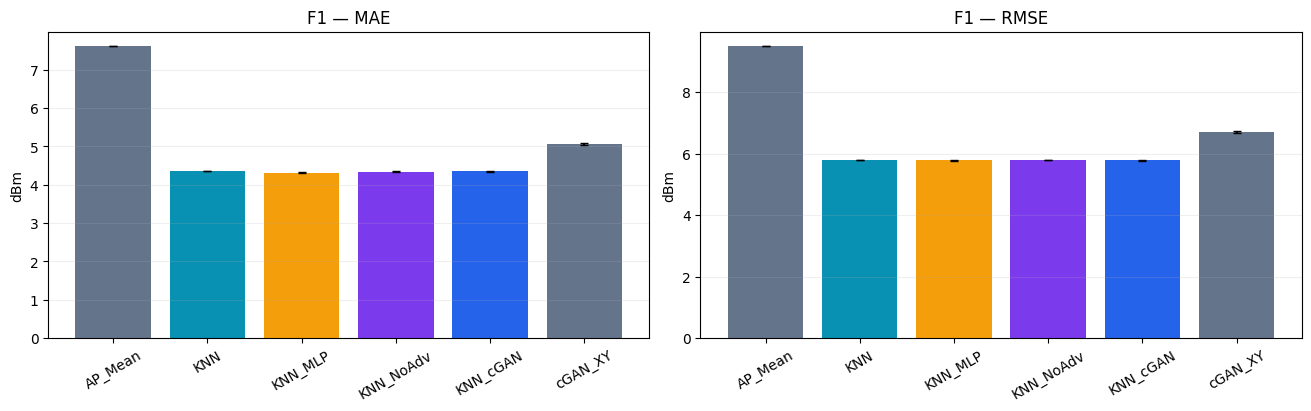

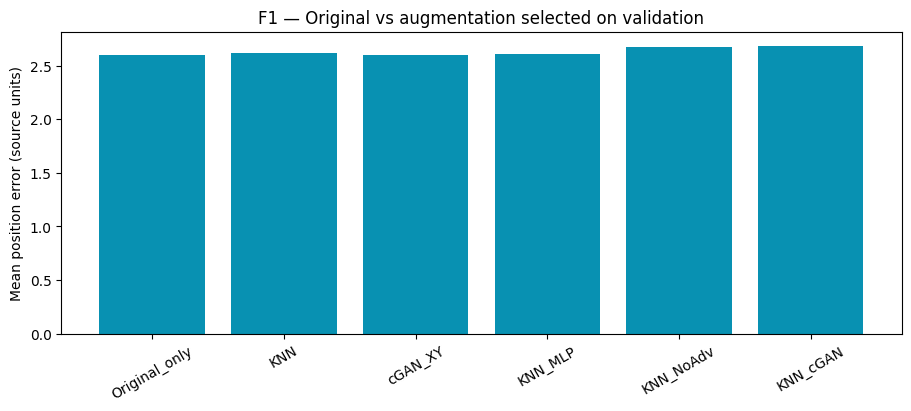

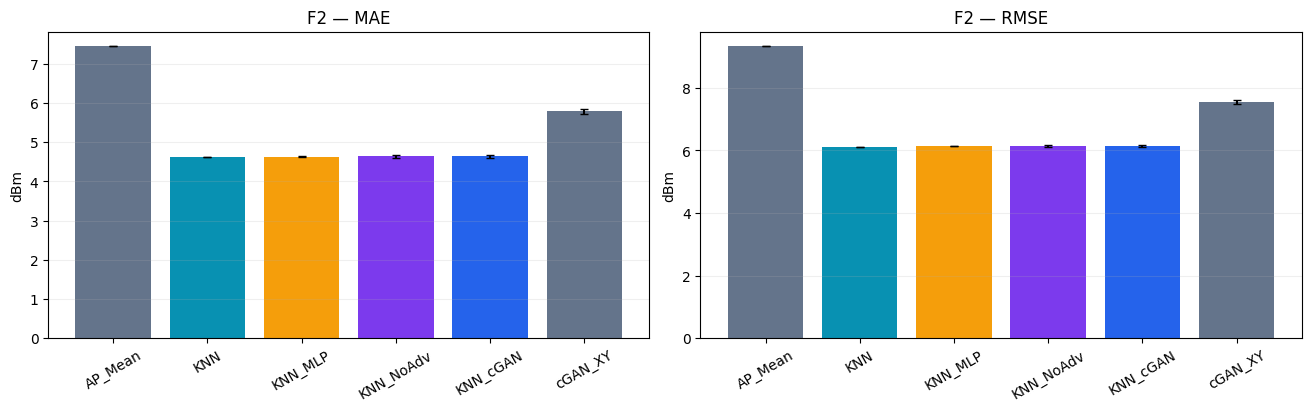

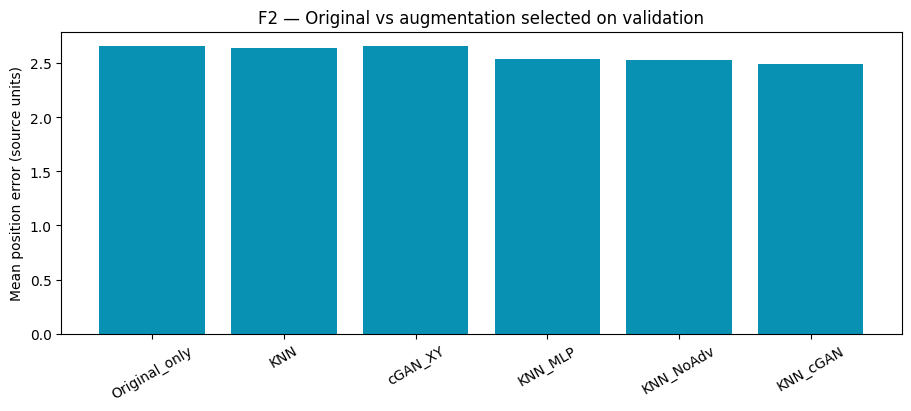

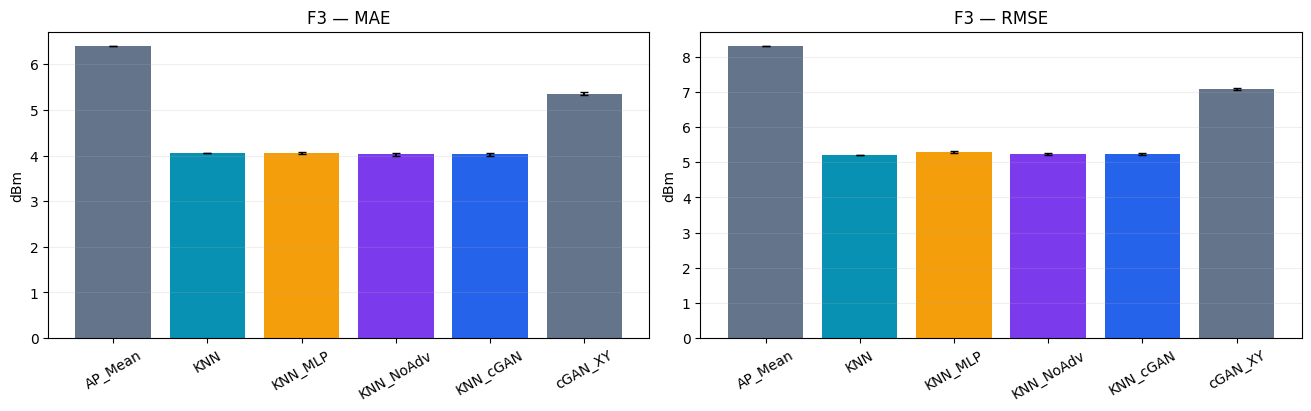

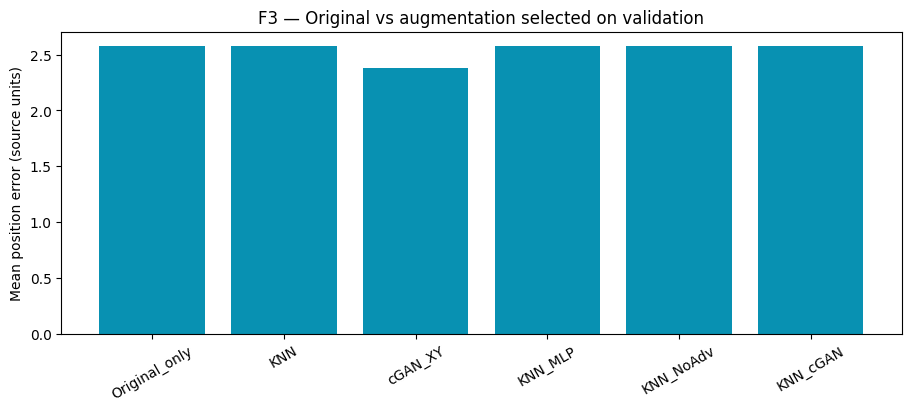

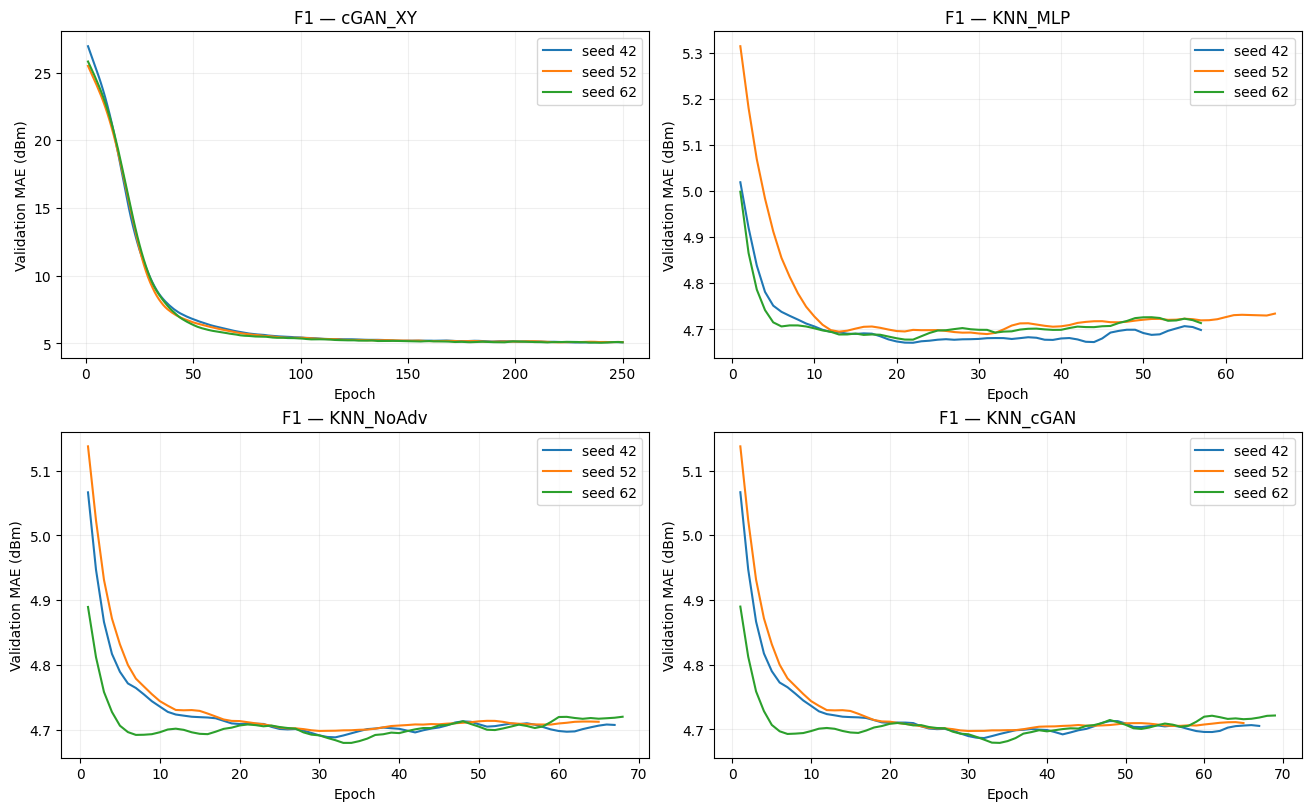

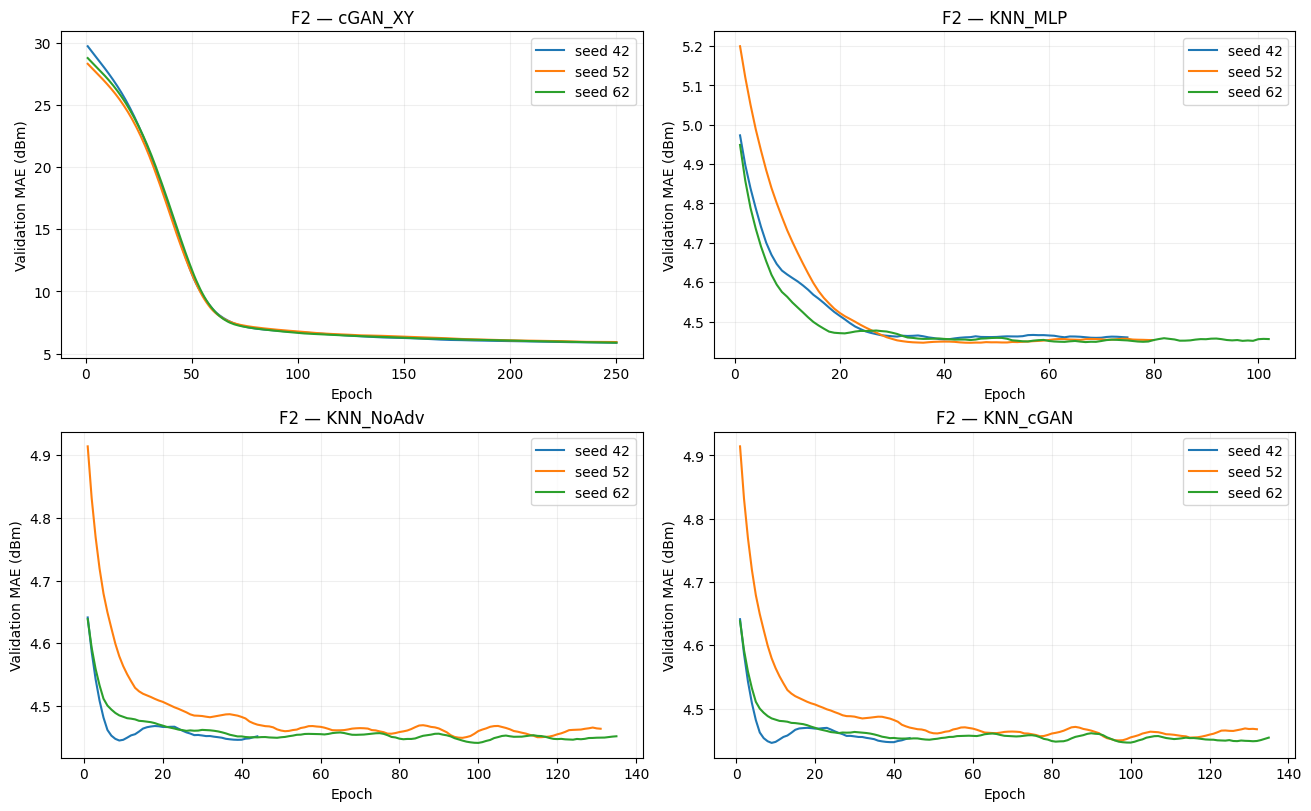

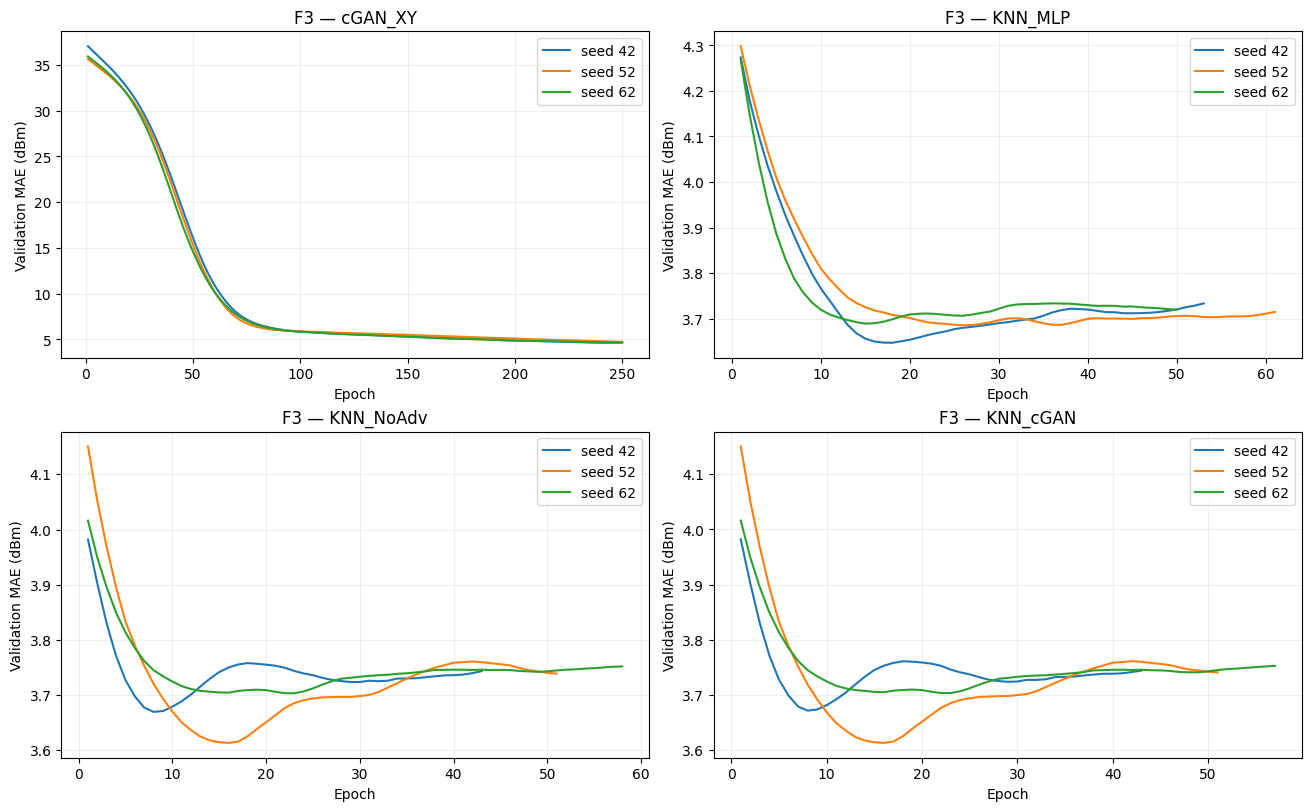

Đã lưu: /content/KNN_CGAN_NEW_results.zip


In [14]:
display(results['summary'])
display(results['localization'])
results_zip = plot_results(results)
print('Đã lưu:', results_zip.resolve())

## 15. Ví dụ sinh fingerprint tại tọa độ chưa khảo sát

Ví dụ chỉ minh họa cách gọi; tự chọn tọa độ trong vùng khảo sát của tầng. File kết quả có 17 RSSI và 17 cờ khả dụng. Đây là dữ liệu **tổng hợp**, không được gắn nhãn số đo thật. Những tọa độ người dùng tự nhập ở bước này không thuộc kết quả định lượng test đã báo cáo.

In [15]:
# Bỏ dấu # khi muốn sử dụng sau khi huấn luyện:
# generated = generate_at_coordinates(cfg['output_dir'], 'F1', [[10.1, 5.3], [20.3, 8.9]])
# display(generated)
# generated.to_csv(Path(cfg['output_dir']) / 'user_requested_fingerprints.csv', index=False)

## 16. Tải kết quả về máy

ZIP kết quả chứa checkpoint, lịch sử, split manifest, dự đoán held-out, dữ liệu sinh và bảng đánh giá. ZIP được tạo trước cell ví dụ tùy chọn; nếu đã thêm tệp ở cell ví dụ, chạy lại `plot_results(results)` để đóng gói lại trước khi tải.

In [16]:
try:
    from google.colab import files
    files.download(str(results_zip))
except ImportError:
    print('Mở thư mục này để lấy kết quả:', results_zip.resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Giới hạn và khả năng tái lập

Đây là mã nghiên cứu mới, chưa có bảo đảm vượt KNN. Kiểm tra khói cục bộ được thực hiện với 4 epoch, 1 seed trên 3 tầng để xác nhận pipeline chạy, **không phải kết quả huấn luyện đầy đủ**. Notebook phát hành giữ trống output để bạn chạy nghiên cứu thật.

Các siêu tham số khởi đầu chưa được tìm kiếm tối ưu. Test giữ vị trí chưa khảo sát là mô phỏng từ dữ liệu có sẵn; không thay thế triển khai hiện trường. Quan hệ giữa hai workbook Train/Test về phiên đo và quy trình thu thập cần xác nhận từ tài liệu nguồn. Không suy ra đơn vị mét chỉ từ tên X/Y. Nhiễu Generator không được xem là độ bất định đã hiệu chỉnh; L1 có thể làm Generator ít dùng nhiễu, cần kiểm tra đa dạng ở nghiên cứu tiếp theo. Seed cố định không bảo đảm bit-identical giữa mọi GPU/phần mềm.